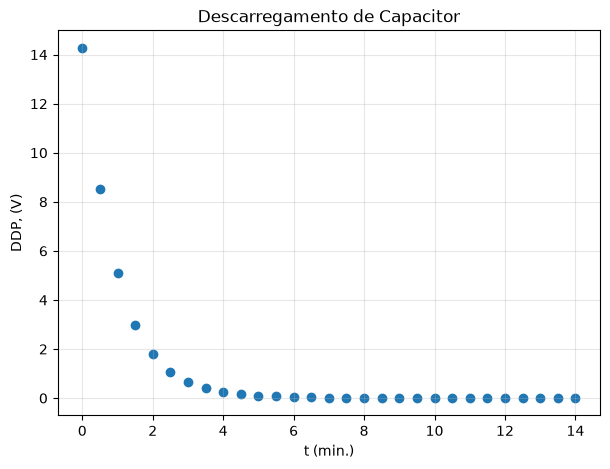

[ 0.   0.5  1.   1.5  2.   2.5  3.   3.5  4.   4.5  5.   5.5  6.   6.5
  7.   7.5  8.   8.5  9.   9.5 10.  10.5 11.  11.5 12.  12.5 13.  13.5
 14. ]
[14.27, 8.53, 5.09, 2.97, 1.79, 1.071, 0.648, 0.4, 0.245, 0.157, 0.103, 0.067, 0.044, 0.03, 0.0225, 0.0169, 0.0132, 0.0108, 0.0092, 0.008, 0.0072, 0.0065, 0.006, 0.0055, 0.0051, 0.0048, 0.0045, 0.0043, 0.0041]


In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import curve_fit

# Cria a sequência de 0.0 até 15.0 (exclusivo), pulando de 0.5 em 0.5
t = np.arange(0.0, 14.5, 0.5)

ddp = [14.27, 8.53, 5.09, 2.97, 1.79, 1.071, .648, .4, .245, .157,
       .103, .067, .044, .03, .0225, .0169, .0132, .0108, .0092,
       .008, .0072, .0065, .006, .0055, .0051, .0048, .0045, .0043,
       .0041]

fig, ax = plt.subplots(figsize=(7, 5))
ax.set_xlabel(r"t (min.)")
ax.set_ylabel(r"DDP, (V)")
ax.set_title("Descarregamento de Capacitor")
ax.grid(True, alpha=0.3)
ax.scatter(t, ddp)
plt.show()

print(t)
print(ddp)



In [2]:
def modelo_exponencial(t, a, b, c):
    return a * np.exp(-b * t) + c

In [ ]:
parametros, covariancia = curve_fit(
    modelo_exponencial,
    t,
    ddp,
    p0=[14, 1, 0]
)

a, b, c = parametros

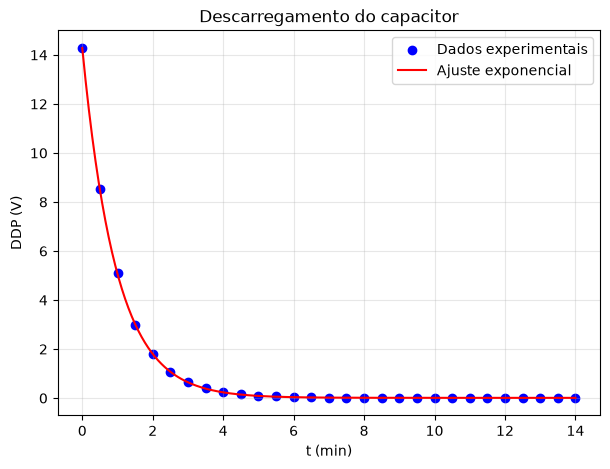

In [6]:
t_curva = np.linspace(t.min(), t.max(), 300)
ddp_curva = modelo_exponencial(t_curva, a, b, c)

fig, ax = plt.subplots(figsize=(7, 5))

ax.scatter(
    t,
    ddp,
    label="Dados experimentais",
    color="blue"
)

ax.plot(
    t_curva,
    ddp_curva,
    label="Ajuste exponencial",
    color="red"
)

ax.set_xlabel("t (min)")
ax.set_ylabel("DDP (V)")
ax.set_title("Descarregamento do capacitor")
ax.grid(True, alpha=0.3)
ax.legend()

plt.show()